In [78]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from typing import List, Callable




Vector = List[float]

In [79]:
data = pd.read_csv('../cities_coord.csv')
data.head()

,Город,Долгота,Широта
0,Москва,55.7558,37.6173
1,Санкт-Петербург,59.9343,30.3351
2,Новосибирск,55.0084,82.9357
3,Екатеринбург,56.8389,60.6057
4,Казань,55.8304,49.0661


In [80]:
data.shape

(20, 3)

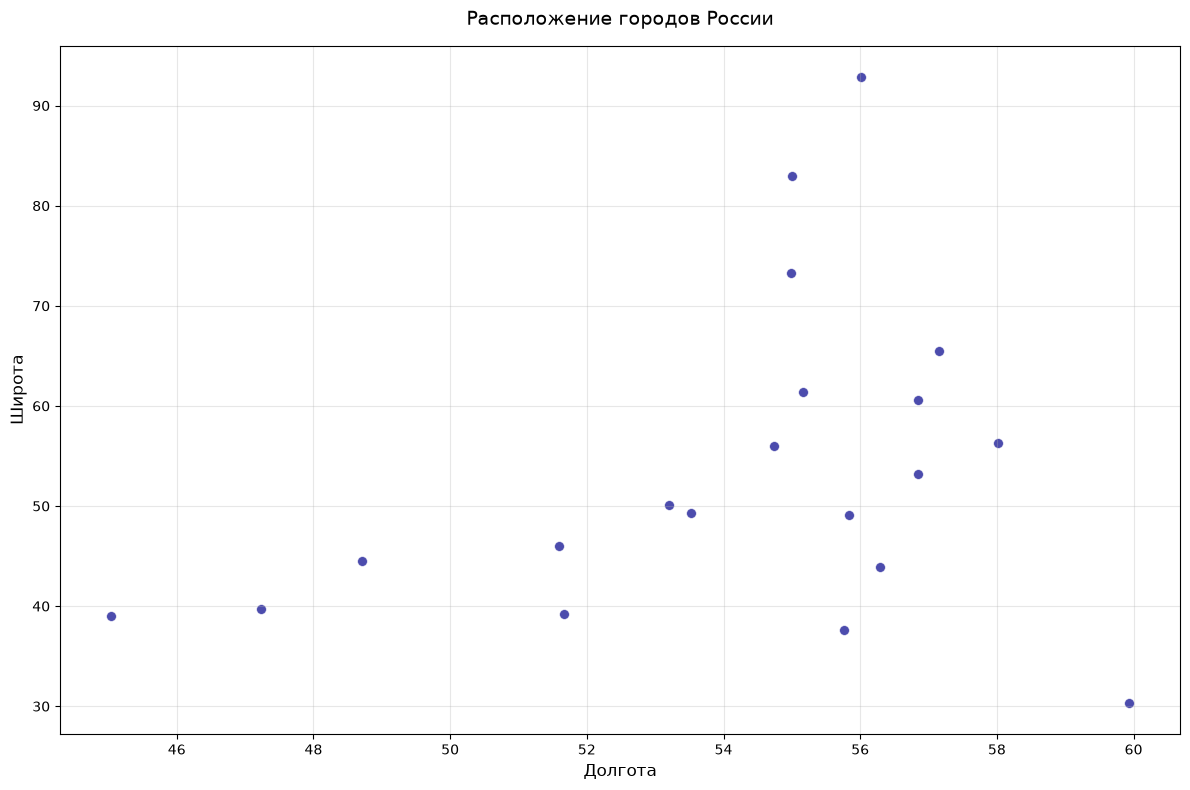

In [81]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=data, 
    x='Долгота', 
    y='Широта',
    color='darkblue',
    s=50,           # размер точек
    alpha=0.7,
    edgecolor='white'
)

plt.title('Расположение городов России', fontsize=14, pad=15)
plt.xlabel('Долгота', fontsize=12)
plt.ylabel('Широта', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [82]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """Расчет расстояния между двумя точками на сфере в километрах"""
    R = 6371  # Средний радиус Земли в км
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2)**2
    
    # 🛡 ИСПРАВЛЕНИЕ 1: Защита от ошибок округления float. 
    # Ограничиваем 'a' диапазоном [0, 1], чтобы корень не ушел в NaN
    a = np.clip(a, 0.0, 1.0) 
    
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

In [83]:
def ant_colony(df, n_ants=40, n_iterations=300, decay=0.7, alpha=1, beta=4, Q=100):
    # 🛡 Используем iloc, чтобы не зависеть от перепутанных заголовков в CSV
    cities = df.iloc[:, 0].tolist()
    lats = df.iloc[:, 1].values  # Фактически широта
    lons = df.iloc[:, 2].values  # Фактически долгота
    n_cities = len(cities)
    
    # Матрица расстояний
    dist_matrix = np.zeros((n_cities, n_cities))
    for i in range(n_cities):
        for j in range(n_cities):
            dist_matrix[i, j] = haversine_distance(lats[i], lons[i], lats[j], lons[j])
            
    heuristic = 1.0 / (dist_matrix + np.eye(n_cities))
    pheromone = np.ones((n_cities, n_cities))
    
    best_path = None
    best_distance = float('inf')
    history = []
    
    for iteration in range(n_iterations):
        all_paths = []
        for _ in range(n_ants):
            visited = np.zeros(n_cities, dtype=bool)
            path = []
            current_city = np.random.randint(0, n_cities)
            path.append(current_city)
            visited[current_city] = True
            
            for _ in range(n_cities - 1):
                unvisited = np.where(~visited)[0]
                tau = pheromone[current_city, unvisited] ** alpha
                eta = heuristic[current_city, unvisited] ** beta
                probs = tau * eta
                
                # 🛡 ИСПРАВЛЕНИЕ 2: Защита от деления на ноль (underflow)
                probs_sum = probs.sum()
                if probs_sum == 0 or np.isnan(probs_sum):
                    # Если все вероятности "обнулились", делаем равномерное распределение
                    probs = np.ones_like(probs) / len(probs)
                else:
                    probs /= probs_sum
                
                next_city = np.random.choice(unvisited, p=probs)
                path.append(next_city)
                visited[next_city] = True
                current_city = next_city
                
            path.append(path[0])
            dist = sum(dist_matrix[path[i], path[i+1]] for i in range(n_cities))
            all_paths.append((path, dist))
            
        min_path, min_dist = min(all_paths, key=lambda x: x[1])
        if min_dist < best_distance:
            best_distance = min_dist
            best_path = min_path
        history.append(best_distance)
        
        pheromone *= (1 - decay)
        
        for path, dist in all_paths:
            for i in range(n_cities):
                u, v = path[i], path[i+1]
                pheromone[u, v] += Q / dist
                pheromone[v, u] += Q / dist
                
    best_city_names = [cities[i] for i in best_path]
    coordinates = np.column_stack((lons, lats)) # X = Долгота, Y = Широта
    
    return best_city_names, best_distance, history, coordinates, cities

In [84]:
coordinates = data

best_route, best_dist, history, coords, city_names = ant_colony(
        data, 
        n_ants=100,          # Количество муравьев
        n_iterations=1000,   # Количество итераций
        decay=0.7,          # Скорость испарения феромона
        alpha=3,            # Влияние феромона
        beta=5,             # Влияние расстояния (жадность)
        Q=100               # Количество феромона
    )

In [85]:
print("🏆 Лучший найденный маршрут:")
print(" ➔ ".join(best_route))
print(f"\n📏 Общая длина маршрута: {best_dist:.2f} км")

🏆 Лучший найденный маршрут:
Новосибирск ➔ Красноярск ➔ Омск ➔ Тюмень ➔ Екатеринбург ➔ Пермь ➔ Ижевск ➔ Казань ➔ НижнийНовгород ➔ Москва ➔ Санкт-Петербург ➔ Воронеж ➔ Краснодар ➔ Ростов-на-Дону ➔ Волгоград ➔ Саратов ➔ Тольятти ➔ Самара ➔ Уфа ➔ Челябинск ➔ Новосибирск

📏 Общая длина маршрута: 10153.23 км


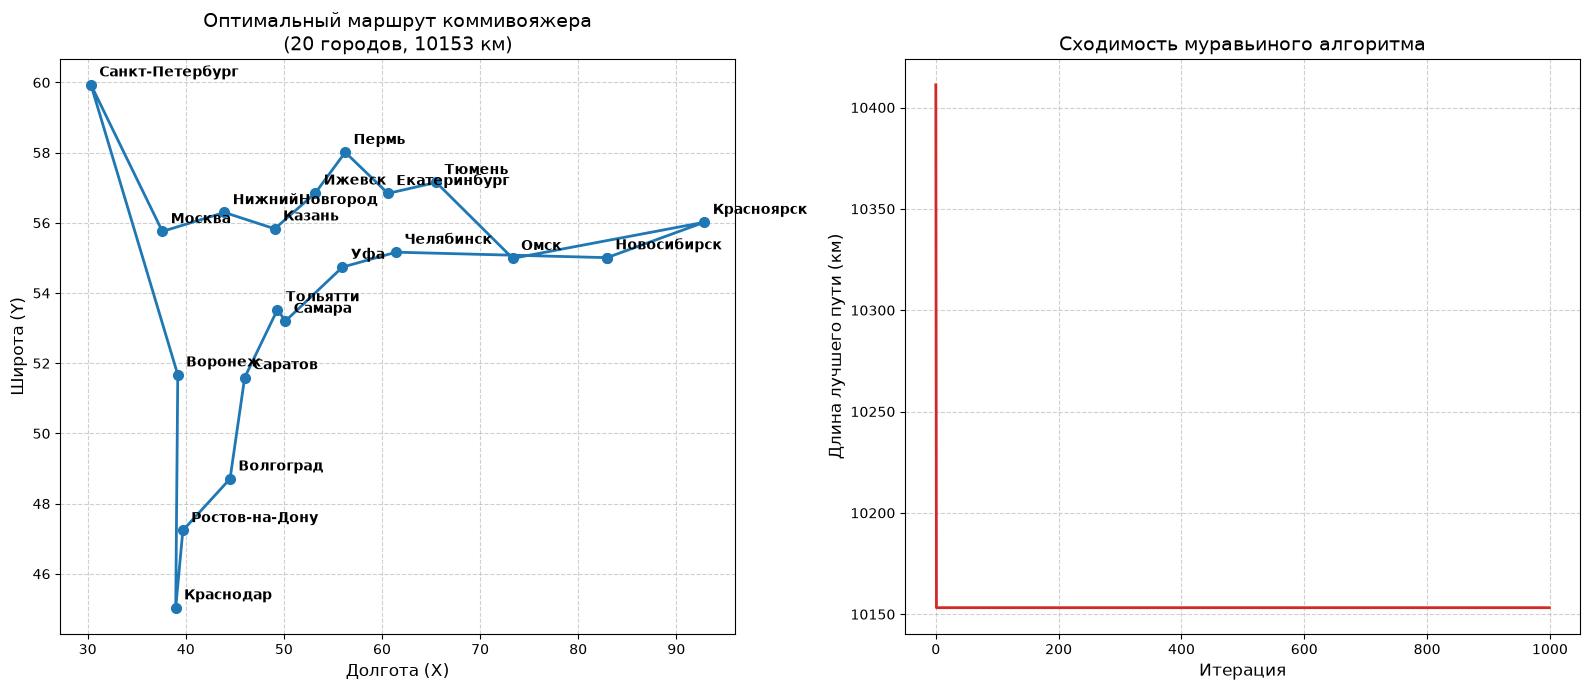

In [89]:
# ==========================================
# Визуализация результатов
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# 🛡 ИСПРАВЛЕНИЕ: Используем city_names вместо cities
route_indices = [city_names.index(city) for city in best_route[:-1]]
route_coords = coords[route_indices]
route_coords_closed = np.vstack([route_coords, route_coords[0]])

# График 1: Карта маршрута
ax1.plot(route_coords_closed[:, 0], route_coords_closed[:, 1], 
         marker='o', linestyle='-', color='#1f77b4', markersize=7, linewidth=2)

# Подписи городов на карте
for i, city in enumerate(city_names):
    ax1.annotate(city, (coords[i, 0], coords[i, 1]), 
                 textcoords="offset points", xytext=(6, 6), 
                 ha='left', fontsize=10, fontweight='bold')
    
ax1.set_title(f"Оптимальный маршрут коммивояжера\n({len(city_names)} городов, {best_dist:.0f} км)", fontsize=14)
ax1.set_xlabel("Долгота (X)", fontsize=12)
ax1.set_ylabel("Широта (Y)", fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)

# График 2: Сходимость алгоритма
ax2.plot(history, color='#d62728', linewidth=2)
ax2.set_title("Сходимость муравьиного алгоритма", fontsize=14)
ax2.set_xlabel("Итерация", fontsize=12)
ax2.set_ylabel("Длина лучшего пути (км)", fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()